# `joint_de`: joint multi-group differential expression

`pdata.de` compares **two** groups. When an experiment has several conditions, `pdata.joint_de` fits **one** linear model per protein across all of them (`abundance ~ 0 + group`) and then tests any number of contrasts of the group means.

The data are HCT116 lysates spiked with D-2HG or L-2HG (1.5 mM and 15 mM) or a NaCl vehicle, extracted in two detergents (NP40 and DDM), 4 replicates per condition (`docs/assets/hct_2hg_report.parquet`, a reduced DIA-NN report; the 2-hydroxybutyrate runs are left out).

Why one joint model?

- Every contrast uses the residual variance **pooled over all groups**, so it has many more degrees of freedom than a two-group test (here 30 instead of 6), assuming the within-group variance is similar across groups.
- Each detergent has its own NaCl vehicle, and the question "does the metabolite act differently in NP40 and DDM?" is a contrast of four groups. `de` cannot test that; `joint_de` can.
- `method='limma'` (default) also shrinks each protein's variance towards a prior shared across proteins; `method='lm'` is the plain pooled-variance t-test. Both give identical `log2fc`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scpviz import pAnnData
from scpviz import plotting as scplt

## Load the data and attach the sample sheet

In [2]:
pdata = pAnnData.import_data(
    source_type='diann',
    report_file='../docs/assets/hct_2hg_report.parquet',
    obs_columns=['date', 'cell_line', 'acquisition', None, 'position', 'sample_position', None, None],
)

ref = pd.read_csv('../docs/assets/hct_2hg_reference.csv', encoding='utf-8-sig').set_index('tip_position')
cols = ['metabolite', 'concentration', 'replicate', 'detergent']

# two tubes were swapped at the bench (tubes 3-2 <-> 2-3)
ref.loc[['S3-B4', 'S3-C5'], cols] = ref.loc[['S3-C5', 'S3-B4'], cols].values

df = pdata.summary
df.drop(columns=df.columns[df.columns.str.startswith('drop')], inplace=True)
for col in cols:
    df[col] = df['sample_position'].map(ref[col])
    assert df[col].notna().all()

# one group label per detergent x metabolite x concentration; NaCl is the vehicle
df['group'] = np.where(df['metabolite'] == 'NaCl',
                       df['detergent'] + '_NaCl',
                       df['detergent'] + '_' + df['metabolite'] + '_' + df['concentration'])
pdata.update_summary(recompute=False)

🧭 [USER] Importing data of type [diann]
--------------------------
Starting import [DIA-NN]

Source file: ../docs/assets/hct_2hg_report.parquet


Number of files: 40
Proteins: 10366


Peptides: 28997

     ℹ️ [INFO] Using sample-specific q-values for 'prot' significance annotation.
     ℹ️ [INFO] Using sample-specific q-values for 'pep' significance annotation.

ℹ️ RS matrix: (10366, 28997) (proteins × peptides), sparsity: 99.99%
   - Proteins with ≥2 *unique* linked peptides: 9299/10366
   - Peptides linked to ≥2 proteins: 321/28997
   - Mean peptides per protein: 2.84
   - Mean proteins per peptide: 1.02
     ✅ [OK] pAnnData object is valid.
     ✅ [OK] Import complete. Use `print(pdata)` to view the object.
--------------------------


🔄 [UPDATE] Updating summary [sync_back]: pushed edits from `.summary` to `.obs` (marked stale).
      Columns updated: metabolite, concentration, group, detergent, replicate.


## Filter, normalize, log2-transform

`joint_de` needs a **log-transformed layer** and raises otherwise (it never logs for you). Normalize on the linear scale first, then `log_transform`. Zeros are treated as missing. Sparse proteins are not filtered inside `joint_de`, so filter them upstream: the limma prior is fitted on whatever proteins you pass in.

In [3]:
pdata = pdata.filter_prot_significant()
pdata = pdata.filter_sample(min_prot=6000)
pdata = pdata.filter_prot_found(min_ratio=0.75, group=['metabolite', 'detergent'], match_any=True)
pdata = pdata.filter_prot(valid_genes=True, unique_profiles=True)

pdata.normalize(method='median')
pdata.log_transform(base=2)
pdata.summary['group'].value_counts().sort_index()

🧭 [USER] Filtering proteins [Significance|File-mode]:
     ℹ️ [INFO] No group provided. Defaulting to sample-level significance filtering.
    Returning a copy of protein data based on significance thresholds:
     🔸 Files requested: All
     🔸 FDR threshold: 0.01
     🔸 Logic: any (protein must be significant in ≥1 file(s))
    → Proteins kept: 10366, Proteins dropped: 0
     ✅ [OK] RS matrix filtered: 10366 proteins, 28997 peptides retained.



🧭 [USER] Filtering samples [condition]:
    Returning a copy of sample data based on condition:
     🔸 Condition: protein_count >= 6000
     ℹ️ Auto-cleanup: No empty proteins found (all-NaN or all-zero).
    → Samples kept: 40, Samples dropped: 0
    → Proteins kept: 10366

     ⚠️ [WARN] class_value 'L-2HG_NP40' contains an underscore ('_'), which may break format_class_filter(). Consider removing or replacing ('_').
     ⚠️ [WARN] class_value 'D-2HG_DDM' contains an underscore ('_'), which may break format_class_filter(). Consider removing or replacing ('_').
     ⚠️ [WARN] class_value 'NaCl_NP40' contains an underscore ('_'), which may break format_class_filter(). Consider removing or replacing ('_').


     ⚠️ [WARN] class_value 'NaCl_DDM' contains an underscore ('_'), which may break format_class_filter(). Consider removing or replacing ('_').
     ⚠️ [WARN] class_value 'L-2HG_DDM' contains an underscore ('_'), which may break format_class_filter(). Consider removing or replacing ('_').
     ⚠️ [WARN] class_value 'D-2HG_NP40' contains an underscore ('_'), which may break format_class_filter(). Consider removing or replacing ('_').


🧭 [USER] Filtering proteins [Found|Group-mode|ANY]:
     ℹ️ [INFO] Found matching groups(s): ['L-2HG_NP40', 'D-2HG_DDM', 'NaCl_NP40', 'NaCl_DDM', 'L-2HG_DDM', 'D-2HG_NP40']. Automatically annotating detection by group values.
    Returning a copy of protein data based on detection thresholds:
     🔸 Groups requested: ['L-2HG_NP40', 'D-2HG_DDM', 'NaCl_NP40', 'NaCl_DDM', 'L-2HG_DDM', 'D-2HG_NP40']
     🔸 Minimum ratio: 0.75
     🔸 Logic: any (protein must be detected in ≥1 group(s))
    → Proteins kept: 10019, Proteins dropped: 347
     ✅ [OK] RS matrix filtered: 10019 proteins, 28489 peptides retained.



🧭 [USER] Filtering proteins [valid genes, unique profiles]:
    Returning a copy of protein data with the following filters applied:
     🔸 valid_genes — removed 26 proteins with invalid gene names
     🔸 valid_genes — resolved 561 duplicate gene names by appending numeric suffixes
     🔸 unique_profiles — removed 182 duplicate and 0 empty abundance profiles (182 total)
    → Proteins kept: 9811
    → Peptides kept (linked): 28429
     ✅ [OK] RS matrix filtered: 9811 proteins, 28429 peptides retained.
🧭 [USER] Global normalization using 'median'. Layer will be saved as 'X_norm_median'.
     ✅ Normalized all 40 samples.
     ℹ️ Set protein data to layer X_norm_median.
🧭 [USER] Log-transforming [protein] layer: 'X' → 'X_log2'
     🔸 base: 2 log base (pseudocount 1.0)
     ✅ Log transform complete. Results stored in:
       • .prot.layers['X_log2']
       • .prot.X updated
       • .prot.uns['layer_provenance']['X_log2'] updated
     ℹ️ Set protein data to layer X_log2.


group
DDM_D-2HG_1.5mM     4
DDM_D-2HG_15mM      4
DDM_L-2HG_1.5mM     4
DDM_L-2HG_15mM      4
DDM_NaCl            4
NP40_D-2HG_1.5mM    4
NP40_D-2HG_15mM     4
NP40_L-2HG_1.5mM    4
NP40_L-2HG_15mM     4
NP40_NaCl           4
Name: count, dtype: int64

## Inspect the CVs first

`joint_de` pools the residual variance over **all** groups in the fit, so it is worth checking that the groups are similarly noisy before testing. The coefficient of variation (CV) per group is a quick look. Compute it on the **normalized linear** layer (`X_norm_median`), not the log2 layer: a CV is a ratio of spread to mean, which only makes sense on the original intensity scale. Proteins with a missing value in a group have no CV there, so the violins describe the proteins observed in all 4 replicates.

`annotate='median'` prints each group's median CV above its violin (every group has 4 replicates).

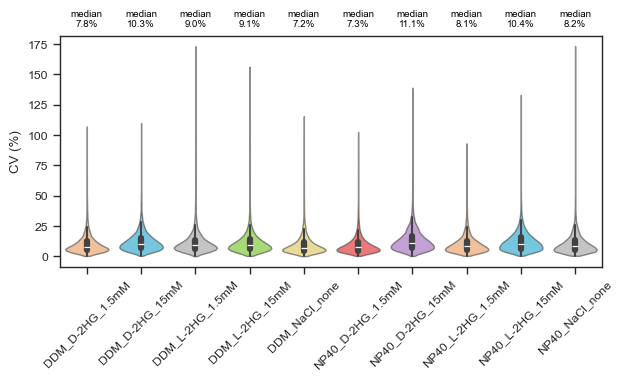

In [4]:
classes = ['detergent', 'metabolite', 'concentration']
fig, ax = plt.subplots(figsize=(7, 3))
scplt.plot_cv(ax, pdata, classes=classes, layer='X_norm_median', annotate='median',
              annotate_kwargs={'fontsize': 7})
ax.tick_params(axis='x', rotation=45)
plt.show()

In [5]:
cv_df = scplt.plot_cv(None, pdata, classes=classes, layer='X_norm_median', return_df=True)
cv_df.groupby('Class', observed=True)['CV_pct'].agg(median='median', proteins='count').round(1)

,median,proteins
Class,,
DDM_D-2HG_1.5mM,7.8,9395
DDM_D-2HG_15mM,10.3,9311
DDM_L-2HG_1.5mM,9.0,9338
DDM_L-2HG_15mM,9.1,9386
DDM_NaCl_none,7.2,9353
NP40_D-2HG_1.5mM,7.3,8288
NP40_D-2HG_15mM,11.1,8273
NP40_L-2HG_1.5mM,8.1,8323
NP40_L-2HG_15mM,10.4,8043


Reading this for `joint_de`: the median CVs here range from about 7% to 11%, a spread of about 1.5-fold, so one shared residual variance is a reasonable working assumption. The 15 mM groups are consistently a little noisier (about 10-11%) than the 1.5 mM and NaCl groups (about 7-9%) in both detergents, which is worth keeping in mind when reading the 15 mM contrasts. A much larger imbalance (for example, one group with twice the median CV of the others) would let its proteins dominate the pooled variance and make tests of the quieter groups anti-conservative. In that case restrict the samples first (section 1 does this for NP40).

## 1. One reference, several comparisons

The simplest call: one shared control (`reference`) and a list of groups to test against it (`comparisons`); `log2fc = comparison - reference`.

Within a single detergent there is one vehicle, so first keep only the NP40 samples. (The model is fitted on every sample you give it, so restrict upstream if the groups are not comparable. Pooling NP40 and DDM would mix two detergents' variances into one estimate.)

**What goes into this fit.** `np40` holds the 20 NP40 samples: the 5 groups `NP40_NaCl`, `NP40_D-2HG_1.5mM`, `NP40_D-2HG_15mM`, `NP40_L-2HG_1.5mM`, `NP40_L-2HG_15mM`, 4 replicates each. `groupby='group'` is the column that defines the groups; `reference` is the control and each entry of `comparisons` is tested against it. The small helper `show_model` (defined below, and reused in later sections) prints the groups in the fit and the weights of every contrast, so it is always clear what a call used.

In [6]:
def show_model(res):
    meta = res['meta']
    print('Groups in the fit (n samples):', ', '.join(f"{g} ({meta['n_samples'][g]})" for g in meta['levels']))
    print('Contrasts:')
    for name, spec in meta['contrasts'].items():
        print(f"  {name}: " + ' '.join(f"{w:+g}*{g}" for g, w in spec.items()))

np40 = pdata.filter_sample(values={'detergent': 'NP40'})
res = np40.joint_de(
    groupby='group',
    reference='NP40_NaCl',
    comparisons=['NP40_D-2HG_1.5mM', 'NP40_D-2HG_15mM', 'NP40_L-2HG_1.5mM', 'NP40_L-2HG_15mM'],
)
show_model(res)

🧭 [USER] Filtering samples [class match]:
    Returning a copy of sample data based on class match:
   🔸 Match samples where:
      - detergent: NP40
     ℹ️ Auto-cleanup: Removed 147 empty proteins (all-NaN or all-zero). Proteins: A0A0C4DGR5, A0A0C4DH89, A0A2R8Y623, A0A590UK28, A0A7I2V5P9, A0A8I5KPG1, A0A8I5KYG9, A0A8V8TQD7, A1IGU5, A6NIX2, ...
    → Samples kept: 20, Samples dropped: 20
    → Proteins kept: 9664

🧭 [USER] Running differential expression [protein]
   🔸 Comparing groups: [{'group': 'NP40_D-2HG_1.5mM'}] vs [{'group': 'NP40_NaCl'}], [{'group': 'NP40_D-2HG_15mM'}] vs [{'group': 'NP40_NaCl'}], [{'group': 'NP40_L-2HG_1.5mM'}] vs [{'group': 'NP40_NaCl'}], [{'group': 'NP40_L-2HG_15mM'}] vs [{'group': 'NP40_NaCl'}]
   🔸 Group sizes: NP40_D-2HG_1.5mM=4, NP40_D-2HG_15mM=4, NP40_L-2HG_1.5mM=4, NP40_L-2HG_15mM=4, NP40_NaCl=4
   🔸 Layer: X (log-transformed)
   🔸 Method: joint limma | groupby=['group'] | 4 contrast(s)
   🔸 Adj p-value threshold: 0.05 | Log2FC threshold: 1.0
     ℹ️ 

The result is a dictionary (also stored in `pdata.stats`, key printed above):

- `res['contrasts']`: one table per contrast with the same columns as `de` (`log2fc`, `p_value`, `adj_p_value`, `significance`, ...) plus `se` and the replicate counts `n_<group>`;
- `res['meta']`: method, group order, contrast weights and the limma prior;
- `res['diagnostics']`: per-protein group counts, residual df, residual variance and (limma) the moderated variance and total df.

In [7]:
print(list(res['contrasts']))
label = list(res['contrasts'])[1]
res['contrasts'][label].head()

["[{'group': 'NP40_D-2HG_1.5mM'}] vs [{'group': 'NP40_NaCl'}]", "[{'group': 'NP40_D-2HG_15mM'}] vs [{'group': 'NP40_NaCl'}]", "[{'group': 'NP40_L-2HG_1.5mM'}] vs [{'group': 'NP40_NaCl'}]", "[{'group': 'NP40_L-2HG_15mM'}] vs [{'group': 'NP40_NaCl'}]"]


,Genes,log2fc,se,p_value,test_statistic,n_NP40_D-2HG_15mM,n_NP40_NaCl,contrast,-log10(p_value),significance_score,adj_p_value,-log10(adj_p_value),significance
O43257,ZNHIT1,1.363839,0.273724,2.924716e-04,4.982530,2,3,[{'group': 'NP40_D-2HG_15mM'}] vs [{'group': '...,3.533916,4.819694,2.344605e-02,1.629930,upregulated
Q8IUF8,RIOX2,1.231414,0.105158,1.155823e-09,11.710094,4,4,[{'group': 'NP40_D-2HG_15mM'}] vs [{'group': '...,8.937109,11.005279,2.131106e-06,5.671395,upregulated
Q96Q83,ALKBH3,1.026409,0.083288,5.216720e-10,12.323582,4,4,[{'group': 'NP40_D-2HG_15mM'}] vs [{'group': '...,9.282603,9.527744,1.603098e-06,5.795040,upregulated
Q9NXG6,P4HTM,1.025841,0.057305,1.267361e-12,17.901322,4,4,[{'group': 'NP40_D-2HG_15mM'}] vs [{'group': '...,11.897100,12.204527,5.841901e-09,8.233446,upregulated
Q6ICH7,ASPHD2,1.849658,0.322305,3.715311e-04,5.738842,4,1,[{'group': 'NP40_D-2HG_15mM'}] vs [{'group': '...,3.430005,6.344334,2.807496e-02,1.551681,upregulated


In [8]:
res['diagnostics'].head()

,n_NP40_D-2HG_1.5mM,n_NP40_D-2HG_15mM,n_NP40_L-2HG_1.5mM,n_NP40_L-2HG_15mM,n_NP40_NaCl,df_residual,s2,s2_post,df_total
A0A024R161,4,2,3,3,2,9.0,0.245413,0.198996,11.345771
A0A024R3Z1,1,2,1,3,1,3.0,0.561736,0.324417,5.345771
A0A024RA87,4,4,4,4,4,15.0,0.530631,0.461698,17.345771
A0A024RBG1,4,4,4,4,4,15.0,0.021577,0.021487,17.345771
A0A067XG54,4,4,4,4,4,15.0,0.017682,0.018119,17.345771


## 2. `limma` (default) vs `lm`

Same `log2fc`, different p-values: `lm` uses each protein's own pooled variance, `limma` shrinks it towards a prior estimated from all proteins. The prior is printed once and stored in `res['meta']` (`s2_prior`, `df_prior`, `estimator`).

In [9]:
kw = dict(groupby='group', reference='NP40_NaCl', comparisons=['NP40_D-2HG_15mM'], store=False)
r_limma = np40.joint_de(method='limma', **kw)
r_lm = np40.joint_de(method='lm', **kw)
show_model(r_limma)  # same 5 NP40 groups, one contrast: NP40_D-2HG_15mM - NP40_NaCl
t_limma = next(iter(r_limma['contrasts'].values()))
t_lm = next(iter(r_lm['contrasts'].values())).reindex(t_limma.index)
print('identical log2fc:', np.allclose(t_limma['log2fc'], t_lm['log2fc'], equal_nan=True))
print({k: r_limma['meta'][k] for k in ('estimator', 's2_prior', 'df_prior')})
print('adj p < 0.05  limma:', int((t_limma['adj_p_value'] < 0.05).sum()), ' lm:', int((t_lm['adj_p_value'] < 0.05).sum()))

🧭 [USER] Running differential expression [protein]
   🔸 Comparing groups: [{'group': 'NP40_D-2HG_15mM'}] vs [{'group': 'NP40_NaCl'}]
   🔸 Group sizes: NP40_D-2HG_1.5mM=4, NP40_D-2HG_15mM=4, NP40_L-2HG_1.5mM=4, NP40_L-2HG_15mM=4, NP40_NaCl=4
   🔸 Layer: X (log-transformed)
   🔸 Method: joint limma | groupby=['group'] | 1 contrast(s)
   🔸 Adj p-value threshold: 0.05 | Log2FC threshold: 1.0
     ℹ️ [INFO] 129 zero value(s) in the selected samples treated as missing (NaN).
     ℹ️ [INFO] limma (unequal_df prior estimator): prior df = 2.35, prior variance = 0.0209.
     ✅ DE complete. Contrast "[{'group': 'NP40_D-2HG_15mM'}] vs [{'group': 'NP40_NaCl'}]":
         • Upregulated: 5 | Downregulated: 6 | Not significant: 9208 | Not comparable: 445
     ✅ Results stored in: .stats["joint: groupby=group | ref=NP40_NaCl | method=limma"]
       • Collection: ['contrasts'][<label>] tables (log2fc, p_value, adj_p_value, significance, etc.), 'meta', 'diagnostics'
🧭 [USER] Running differential expressi

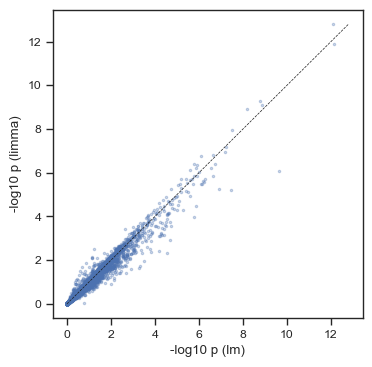

In [10]:
fig, ax = plt.subplots(figsize=(4, 4))
x = -np.log10(t_lm['p_value']); y = -np.log10(t_limma['p_value'])
ax.scatter(x, y, s=3, alpha=0.3)
lim = [0, float(np.nanmax([x.max(), y.max()]))]
ax.plot(lim, lim, 'k--', lw=0.5)
ax.set_xlabel('-log10 p (lm)'); ax.set_ylabel('-log10 p (limma)')
plt.show()

## 3. Joint vs a separate two-group test

Same comparison as section 2 (`NP40_D-2HG_15mM` vs `NP40_NaCl`) with `de`: only those two groups (4 + 4 samples) are used, giving 6 residual df. The joint fit above (`np40`, 5 groups, 20 samples) also borrows the residual variance of the other 3 NP40 groups: 15 residual df.

In [11]:
sep = np40.de(
    values=[{'detergent': 'NP40', 'metabolite': 'D-2HG', 'concentration': '15mM'},
            {'detergent': 'NP40', 'metabolite': 'NaCl'}],
    method='limma', correct_fdr=True,
)
joint = t_limma
print('residual df  joint:', int(r_limma['diagnostics']['df_residual'].median()), ' separate: 6')
print('adj p < 0.05  joint:', int((joint['adj_p_value'] < 0.05).sum()), ' separate:', int((sep['adj_p_value'] < 0.05).sum()))
print('same log2fc:', np.allclose(joint['log2fc'], sep['log2fc'].reindex(joint.index), equal_nan=True))

🧭 [USER] Running differential expression [protein]
   🔸 Comparing groups: [{'detergent': 'NP40', 'metabolite': 'D-2HG', 'concentration': '15mM'}] vs [{'detergent': 'NP40', 'metabolite': 'NaCl'}]
   🔸 Group sizes: 4 vs 4 samples
   🔸 Layer: X (log-transformed)
   🔸 Method: limma | Fold Change: mean
   🔸 Adj p-value threshold: 0.05 | Log2FC threshold: 1.0
     ℹ️ [INFO] 57 zero value(s) in the selected samples treated as missing (NaN) for testing and fold change.
     ℹ️ [INFO] Layer 'X' is log-transformed (log2) — using mean difference for log2FC.
     ℹ️ [INFO] 445 proteins were not comparable (zero or NaN mean in one group).
     ℹ️ [INFO] limma (unequal_df prior estimator): prior df = 2.56, prior variance = 0.0245.
     ✅ DE complete. Results stored in:
       • .stats["[{'detergent': 'NP40', 'metabolite': 'D-2HG', 'concentration': '15mM'}] vs [{'detergent': 'NP40', 'metabolite': 'NaCl'}]"]
       • Columns: log2fc, p_value, adj_p_value, significance, etc.
       • Upregulated: 3 | D

## 4. Detergent-specific vehicles: name the contrasts yourself

With both detergents in one model, each metabolite should be compared with **its own detergent's** NaCl. Pass `contrasts` as `{name: (test, ref)}`.

**What goes into this fit.** The full `pdata`: all 40 samples and all 10 groups (2 detergents x {NaCl, D-2HG 1.5 mM, D-2HG 15 mM, L-2HG 1.5 mM, L-2HG 15 mM}), 30 residual df. There are 8 contrasts; each estimates one metabolite group against the NaCl of the same detergent (for example `NP40_D-2HG_15mM - NP40_NaCl`), and the other groups take part only through the shared residual variance.

In [12]:
doses = [(met, conc) for met in ('D-2HG', 'L-2HG') for conc in ('1.5mM', '15mM')]
pairs = {
    f'{det} {met} {conc} vs NaCl': (f'{det}_{met}_{conc}', f'{det}_NaCl')
    for det in ('NP40', 'DDM') for met, conc in doses
}
res_pairs = pdata.joint_de(groupby='group', contrasts=pairs)
show_model(res_pairs)
summary = pd.DataFrame({
    name: t['significance'].value_counts() for name, t in res_pairs['contrasts'].items()
}).T[['upregulated', 'downregulated']]
summary

🧭 [USER] Running differential expression [protein]
   🔸 Comparing groups: NP40 D-2HG 1.5mM vs NaCl, NP40 D-2HG 15mM vs NaCl, NP40 L-2HG 1.5mM vs NaCl, NP40 L-2HG 15mM vs NaCl, DDM D-2HG 1.5mM vs NaCl, DDM D-2HG 15mM vs NaCl, DDM L-2HG 1.5mM vs NaCl, DDM L-2HG 15mM vs NaCl
   🔸 Group sizes: DDM_D-2HG_1.5mM=4, DDM_D-2HG_15mM=4, DDM_L-2HG_1.5mM=4, DDM_L-2HG_15mM=4, DDM_NaCl=4, NP40_D-2HG_1.5mM=4, NP40_D-2HG_15mM=4, NP40_L-2HG_1.5mM=4, NP40_L-2HG_15mM=4, NP40_NaCl=4
   🔸 Layer: X (log-transformed)
   🔸 Method: joint limma | groupby=['group'] | 8 contrast(s)
   🔸 Adj p-value threshold: 0.05 | Log2FC threshold: 1.0
     ℹ️ [INFO] 236 zero value(s) in the selected samples treated as missing (NaN).
     ℹ️ [INFO] limma (unequal_df prior estimator): prior df = 2.68, prior variance = 0.0229.
     ✅ DE complete. Contrast 'NP40 D-2HG 1.5mM vs NaCl':
         • Upregulated: 0 | Downregulated: 5 | Not significant: 9182 | Not comparable: 624
     ✅ DE complete. Contrast 'NP40 D-2HG 15mM vs NaCl':
   

significance,upregulated,downregulated
NP40 D-2HG 1.5mM vs NaCl,0,5
NP40 D-2HG 15mM vs NaCl,7,9
NP40 L-2HG 1.5mM vs NaCl,1,2
NP40 L-2HG 15mM vs NaCl,8,14
DDM D-2HG 1.5mM vs NaCl,0,0
DDM D-2HG 15mM vs NaCl,0,0
DDM L-2HG 1.5mM vs NaCl,1,0
DDM L-2HG 15mM vs NaCl,0,0


## 5. Interaction contrasts: does the metabolite act differently in the two detergents?

Pass a **weight vector** instead of a pair: `{group: weight}`.

In plain terms:

1. How much does 15 mM D-2HG change a protein **in NP40**? `NP40_D-2HG_15mM - NP40_NaCl`.
2. How much does it change it **in DDM**? `DDM_D-2HG_15mM - DDM_NaCl`.
3. The question "is the effect different between detergents?" is *(change in NP40) - (change in DDM)*.

The weights are just the plus/minus signs that do that subtraction in one step: groups with `+1` are added, groups with `-1` are subtracted, groups you do not list are ignored. The weights must add up to zero so that only differences (never overall levels) are compared:

| group | weight |
|---|---|
| NP40_D-2HG_15mM | +1 |
| NP40_NaCl | -1 |
| DDM_D-2HG_15mM | -1 |
| DDM_NaCl | +1 |

`log2fc` is then (log2 change in NP40) - (log2 change in DDM): close to 0 means the metabolite acts the same in both detergents.

A protein that is significant in NP40 but not in DDM does **not** show that the detergents differ (one test may just be noisier). Only this contrast tests it.

**What goes into these fits.** Again the full `pdata` (40 samples, all 10 groups, 30 residual df). Each of the 4 interaction contrasts (D-2HG and L-2HG at 1.5 and 15 mM) estimates its effect from 4 groups: that metabolite group and the NaCl of NP40, minus the same two groups of DDM. The remaining groups contribute to the residual variance only.

In [13]:
interaction = {
    f'{met} {conc}: NP40 effect - DDM effect': {
        f'NP40_{met}_{conc}': +1, 'NP40_NaCl': -1,
        f'DDM_{met}_{conc}': -1, 'DDM_NaCl': +1,
    }
    for met, conc in doses
}
res_int = pdata.joint_de(groupby='group', contrasts=interaction)
show_model(res_int)

🧭 [USER] Running differential expression [protein]
   🔸 Comparing groups: D-2HG 1.5mM: NP40 effect - DDM effect, D-2HG 15mM: NP40 effect - DDM effect, L-2HG 1.5mM: NP40 effect - DDM effect, L-2HG 15mM: NP40 effect - DDM effect
   🔸 Group sizes: DDM_D-2HG_1.5mM=4, DDM_D-2HG_15mM=4, DDM_L-2HG_1.5mM=4, DDM_L-2HG_15mM=4, DDM_NaCl=4, NP40_D-2HG_1.5mM=4, NP40_D-2HG_15mM=4, NP40_L-2HG_1.5mM=4, NP40_L-2HG_15mM=4, NP40_NaCl=4
   🔸 Layer: X (log-transformed)
   🔸 Method: joint limma | groupby=['group'] | 4 contrast(s)
   🔸 Adj p-value threshold: 0.05 | Log2FC threshold: 1.0
     ℹ️ [INFO] 236 zero value(s) in the selected samples treated as missing (NaN).
     ℹ️ [INFO] limma (unequal_df prior estimator): prior df = 2.68, prior variance = 0.0229.
     ✅ DE complete. Contrast 'D-2HG 1.5mM: NP40 effect - DDM effect':
         • Upregulated: 0 | Downregulated: 4 | Not significant: 9132 | Not comparable: 675
     ✅ DE complete. Contrast 'D-2HG 15mM: NP40 effect - DDM effect':
         • Upregulated:

Other questions are other weight vectors, still on the full `pdata` (all 10 groups). The same machinery gives a dose effect (15 mM vs 1.5 mM, within NP40) and a D- vs L-enantiomer comparison (within NP40, and as a difference between detergents), each in one test:

In [14]:
other = {
    'D-2HG 15mM vs 1.5mM (NP40)': ('NP40_D-2HG_15mM', 'NP40_D-2HG_1.5mM'),
    'D vs L 2HG at 15mM (NP40)': ('NP40_D-2HG_15mM', 'NP40_L-2HG_15mM'),
    'D vs L 2HG at 15mM: NP40 - DDM': {
        'NP40_D-2HG_15mM': +1, 'NP40_L-2HG_15mM': -1,
        'DDM_D-2HG_15mM': -1, 'DDM_L-2HG_15mM': +1,
    },
}
res_other = pdata.joint_de(groupby='group', contrasts=other, store=False)
show_model(res_other)
pd.DataFrame({k: t['significance'].value_counts() for k, t in res_other['contrasts'].items()}).T

🧭 [USER] Running differential expression [protein]
   🔸 Comparing groups: D-2HG 15mM vs 1.5mM (NP40), D vs L 2HG at 15mM (NP40), D vs L 2HG at 15mM: NP40 - DDM
   🔸 Group sizes: DDM_D-2HG_1.5mM=4, DDM_D-2HG_15mM=4, DDM_L-2HG_1.5mM=4, DDM_L-2HG_15mM=4, DDM_NaCl=4, NP40_D-2HG_1.5mM=4, NP40_D-2HG_15mM=4, NP40_L-2HG_1.5mM=4, NP40_L-2HG_15mM=4, NP40_NaCl=4
   🔸 Layer: X (log-transformed)
   🔸 Method: joint limma | groupby=['group'] | 3 contrast(s)
   🔸 Adj p-value threshold: 0.05 | Log2FC threshold: 1.0
     ℹ️ [INFO] 236 zero value(s) in the selected samples treated as missing (NaN).
     ℹ️ [INFO] limma (unequal_df prior estimator): prior df = 2.68, prior variance = 0.0229.
     ✅ DE complete. Contrast 'D-2HG 15mM vs 1.5mM (NP40)':
         • Upregulated: 5 | Downregulated: 7 | Not significant: 9194 | Not comparable: 605
     ✅ DE complete. Contrast 'D vs L 2HG at 15mM (NP40)':
         • Upregulated: 3 | Downregulated: 7 | Not significant: 9220 | Not comparable: 581
     ✅ DE complete. C

significance,not significant,not comparable,downregulated,upregulated
D-2HG 15mM vs 1.5mM (NP40),9194,605,7,5
D vs L 2HG at 15mM (NP40),9220,581,7,3
D vs L 2HG at 15mM: NP40 - DDM,9157,650,3,1


7 [-0.79954781  0.24306114]
9 [0.82157407 0.3555954 ]
6 [ 0.56495641 -0.16809848]
8 [0.18620319 0.77446523]
0 [ 0.10288227 -0.99882439]
2 [ 0.62073379 -0.81677392]


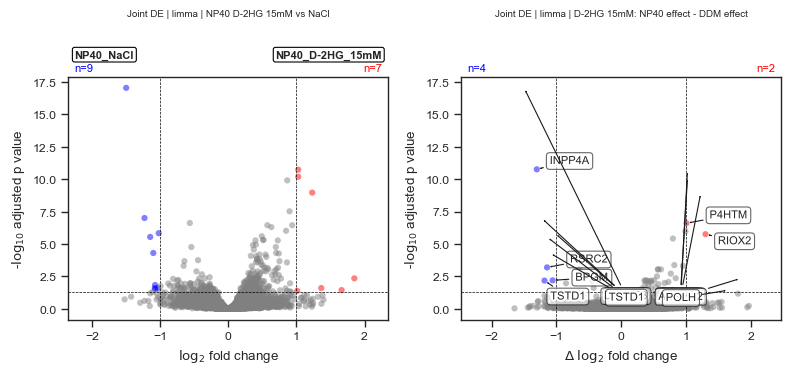

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
name_pair = 'NP40 D-2HG 15mM vs NaCl'
name_int = 'D-2HG 15mM: NP40 effect - DDM effect'
scplt.plot_volcano(axes[0], de_data=res_pairs['contrasts'][name_pair], correct_fdr=True)
scplt.plot_volcano(axes[1], de_data=res_int['contrasts'][name_int], correct_fdr=True)
plt.tight_layout(); plt.show()

### How to read these volcano plots

Every contrast is a subtraction, `effect = (groups with +1) - (groups with -1)`, and the volcano shows that effect as `log2fc` on the x-axis. **Upregulated (right, red)** means the `+1` side is higher; **downregulated (left, blue)** means the `-1` side is higher. A protein is called up/down when `adj_p_value < 0.05` **and** `|log2fc| > 1` (the `threshold` and `log2fc` arguments). For a pair contrast the two group names are printed in the boxes above the plot: the `+1` group on the right and the `-1` group on the left.

| contrast | upregulated means | downregulated means |
|---|---|---|
| `NP40 D-2HG 15mM vs NaCl` | higher with D-2HG than with the NaCl vehicle | lower with D-2HG than with NaCl |
| `D vs L 2HG at 15mM (NP40)` | higher in D-2HG than in L-2HG (NaCl is not involved: this compares the two enantiomers directly) | higher in L-2HG than in D-2HG |
| `D-2HG 15mM: NP40 effect - DDM effect` | D-2HG moves the protein **more upwards in NP40 than in DDM** | D-2HG moves it more upwards in DDM than in NP40 |

**What the interaction volcano is (and is not).** Yes: the proteins called significant in an interaction contrast are the ones with statistical evidence that the metabolite effect **differs between the detergents**. The converse does not hold: a protein that is not significant has no *evidence* of a difference (with 4 replicates a real difference can be missed); it is not shown to be the same. The sign of the interaction `log2fc` also does not say what happens inside each detergent: `+2` can be "up 2 in NP40, unchanged in DDM", "unchanged in NP40, down 2 in DDM" or "up 3 in NP40, up 1 in DDM". To see which, put the per-detergent effects next to the interaction (below), and never replace the interaction contrast by comparing the two significance lists.

In [16]:
name_int = 'D-2HG 15mM: NP40 effect - DDM effect'
inter = res_int['contrasts'][name_int]
np40_eff = res_pairs['contrasts']['NP40 D-2HG 15mM vs NaCl']['log2fc']
ddm_eff = res_pairs['contrasts']['DDM D-2HG 15mM vs NaCl']['log2fc']
table = pd.DataFrame({
    'gene': inter['Genes'],
    'NP40 effect': np40_eff, 'DDM effect': ddm_eff,
    'interaction log2fc': inter['log2fc'], 'interaction adj p': inter['adj_p_value'],
})
table['NP40 effect - DDM effect'] = table['NP40 effect'] - table['DDM effect']  # equals the interaction log2fc
table.sort_values('interaction adj p').head(10).round(3)

,gene,NP40 effect,DDM effect,interaction log2fc,interaction adj p,NP40 effect - DDM effect
Q96PE3,INPP4A,-1.499,-0.197,-1.302,0.000,-1.302
Q9NXG6,P4HTM,1.026,0.016,1.010,0.000,1.010
Q96Q83,ALKBH3,1.026,0.032,0.994,0.000,0.994
Q8IUF8,RIOX2,1.231,-0.071,1.303,0.000,1.303
Q8N543,OGFOD1,0.865,0.065,0.800,0.000,0.800
Q6P6C2,ALKBH5,0.898,0.077,0.821,0.000,0.821
Q96S16,JMJD8,0.938,-0.017,0.955,0.000,0.955
Q7L4I2,RSRC2,-1.230,-0.087,-1.143,0.001,-1.143
Q9H0G5,NSRP1,0.512,-0.055,0.567,0.001,0.567
P18669,PGAM1,-0.542,0.100,-0.643,0.001,-0.643


6 [-0.05591045 -0.76558394]
7 [-0.32593975 -0.13122586]
4 [ 0.57788668 -0.78975752]
7 [ 0.34786183 -0.03046217]


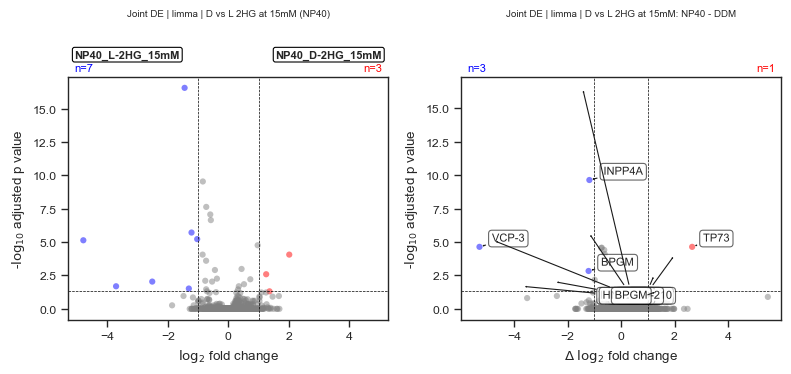

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
for ax, name in zip(axes, ['D vs L 2HG at 15mM (NP40)', 'D vs L 2HG at 15mM: NP40 - DDM']):
    scplt.plot_volcano(ax, de_data=res_other['contrasts'][name], correct_fdr=True)
plt.tight_layout(); plt.show()

### Why `D vs L` needs no NaCl, and how it differs from `de`

It can look as if "D vs L" should be written as `(D - NaCl) - (L - NaCl)`. It does not need to: the NaCl terms cancel exactly, `(D - NaCl) - (L - NaCl) = D - L`. The net weight on NaCl is `-1 + 1 = 0`, so NaCl adds nothing to the estimate or to its variance (the variance of a contrast is `sum(weight**2 / n)` over the groups with non-zero net weight). NaCl only matters when it does **not** cancel, as when each detergent has its own vehicle (the interaction above). One practical consequence: a protein that was never observed in NaCl cannot be tested against NaCl, but `D - L` does not need NaCl, so it can still be tested.

So what does the joint model add for `D vs L`? Not a different `log2fc`: that is the same difference of two group means that a separate `de` gives. It adds the **variance**: the joint fit uses the residual variance of all 10 groups (30 residual df) instead of only the 8 samples of the two groups (6 df), and `limma` fits one prior across all proteins.

In [18]:
dl = res_other['contrasts']['D vs L 2HG at 15mM (NP40)']
d_vs_nacl = res_pairs['contrasts']['NP40 D-2HG 15mM vs NaCl']['log2fc']
l_vs_nacl = res_pairs['contrasts']['NP40 L-2HG 15mM vs NaCl']['log2fc']

# (D - NaCl) - (L - NaCl) reproduces D - L wherever NaCl was observed
padded = (d_vs_nacl - l_vs_nacl).reindex(dl.index)
both = padded.notna() & dl['log2fc'].notna()
print('NaCl cancels where defined:', np.allclose(dl.loc[both, 'log2fc'], padded[both]), f'({int(both.sum())} proteins)')
print('D - L estimable but the NaCl-padded form is not (NaCl never observed):', int((dl['log2fc'].notna() & padded.isna()).sum()))

# the same comparison with a separate two-group de(): same log2fc, different variance
sep_dl = pdata.de(
    values=[{'detergent': 'NP40', 'metabolite': 'D-2HG', 'concentration': '15mM'},
            {'detergent': 'NP40', 'metabolite': 'L-2HG', 'concentration': '15mM'}],
    method='limma', correct_fdr=True,
)
print('same log2fc as separate de():', np.allclose(dl['log2fc'], sep_dl['log2fc'].reindex(dl.index), equal_nan=True))
print('residual df  joint: 30  separate: 6')
print('adj p < 0.05  joint:', int((dl['adj_p_value'] < 0.05).sum()), ' separate:', int((sep_dl['adj_p_value'] < 0.05).sum()))

NaCl cancels where defined: True (9125 proteins)
D - L estimable but the NaCl-padded form is not (NaCl never observed): 105
🧭 [USER] Running differential expression [protein]
   🔸 Comparing groups: [{'detergent': 'NP40', 'metabolite': 'D-2HG', 'concentration': '15mM'}] vs [{'detergent': 'NP40', 'metabolite': 'L-2HG', 'concentration': '15mM'}]
   🔸 Group sizes: 4 vs 4 samples
   🔸 Layer: X (log-transformed)
   🔸 Method: limma | Fold Change: mean
   🔸 Adj p-value threshold: 0.05 | Log2FC threshold: 1.0
     ℹ️ [INFO] 54 zero value(s) in the selected samples treated as missing (NaN) for testing and fold change.
     ℹ️ [INFO] Layer 'X' is log-transformed (log2) — using mean difference for log2FC.
     ℹ️ [INFO] 581 proteins were not comparable (zero or NaN mean in one group).
     ℹ️ [INFO] limma (unequal_df prior estimator): prior df = 2.73, prior variance = 0.0296.
     ✅ DE complete. Results stored in:
       • .stats["[{'detergent': 'NP40', 'metabolite': 'D-2HG', 'concentration': '15m

## 6. Multiple-testing scope

These runs repeat the 8 detergent-specific contrasts of section 4 (full `pdata`, all 10 groups). `fdr_scope='per_contrast'` (default) applies Benjamini-Hochberg across proteins separately within each contrast. `'global'` applies it once over every protein x contrast p-value; `'both'` keeps the per-contrast `adj_p_value` and adds `adj_p_value_global`.

In [19]:
res_both = pdata.joint_de(groupby='group', contrasts=pairs, fdr_scope='both', store=False)
pd.DataFrame({
    'per_contrast': {k: int((t['adj_p_value'] < 0.05).sum()) for k, t in res_both['contrasts'].items()},
    'global': {k: int((t['adj_p_value_global'] < 0.05).sum()) for k, t in res_both['contrasts'].items()},
})

🧭 [USER] Running differential expression [protein]
   🔸 Comparing groups: NP40 D-2HG 1.5mM vs NaCl, NP40 D-2HG 15mM vs NaCl, NP40 L-2HG 1.5mM vs NaCl, NP40 L-2HG 15mM vs NaCl, DDM D-2HG 1.5mM vs NaCl, DDM D-2HG 15mM vs NaCl, DDM L-2HG 1.5mM vs NaCl, DDM L-2HG 15mM vs NaCl
   🔸 Group sizes: DDM_D-2HG_1.5mM=4, DDM_D-2HG_15mM=4, DDM_L-2HG_1.5mM=4, DDM_L-2HG_15mM=4, DDM_NaCl=4, NP40_D-2HG_1.5mM=4, NP40_D-2HG_15mM=4, NP40_L-2HG_1.5mM=4, NP40_L-2HG_15mM=4, NP40_NaCl=4
   🔸 Layer: X (log-transformed)
   🔸 Method: joint limma | groupby=['group'] | 8 contrast(s)
   🔸 Adj p-value threshold: 0.05 | Log2FC threshold: 1.0
     ℹ️ [INFO] 236 zero value(s) in the selected samples treated as missing (NaN).
     ℹ️ [INFO] limma (unequal_df prior estimator): prior df = 2.68, prior variance = 0.0229.
     ✅ DE complete. Contrast 'NP40 D-2HG 1.5mM vs NaCl':
         • Upregulated: 0 | Downregulated: 5 | Not significant: 9182 | Not comparable: 624
     ✅ DE complete. Contrast 'NP40 D-2HG 15mM vs NaCl':
   

,per_contrast,global
NP40 D-2HG 1.5mM vs NaCl,13,15
NP40 D-2HG 15mM vs NaCl,251,125
NP40 L-2HG 1.5mM vs NaCl,12,12
NP40 L-2HG 15mM vs NaCl,173,93
DDM D-2HG 1.5mM vs NaCl,0,0
DDM D-2HG 15mM vs NaCl,0,0
DDM L-2HG 1.5mM vs NaCl,1,1
DDM L-2HG 15mM vs NaCl,0,2


## 7. Diagnostics and missing values

The tables below come from the section 4 fit (full `pdata`, 10 groups, 8 contrasts). Each protein is fitted on the samples where it was observed. A contrast is only estimable when every group in it has at least one observation; otherwise `log2fc`, `p_value` ... are `NaN` and the protein is labelled `not comparable` (it still contributes its variance to the prior). `n_<group>` and `df_residual` show the support behind each test.

In [20]:
diag = res_pairs['diagnostics']
n_cols = [c for c in diag.columns if c.startswith('n_')]
print('residual df (complete proteins = 30):'); print(diag['df_residual'].value_counts().sort_index().tail(5))
print('proteins missing a whole group:', int((diag[n_cols] == 0).any(axis=1).sum()))
print({k: int((t['significance'] == 'not comparable').sum()) for k, t in list(res_pairs['contrasts'].items())[:3]})

residual df (complete proteins = 30):
df_residual
26.0     105
27.0     121
28.0     178
29.0     341
30.0    7522
Name: count, dtype: int64
proteins missing a whole group: 873
{'NP40 D-2HG 1.5mM vs NaCl': 624, 'NP40 D-2HG 15mM vs NaCl': 592, 'NP40 L-2HG 1.5mM vs NaCl': 611}


## When not to use `joint_de`

- **Paired or repeated measurements** (same donor, animal or plex measured in several conditions): samples are assumed independent here. Use `mixed_de`.
- **Groups with very different variance**: they share one residual variance per protein. Restrict the samples first (`filter_sample`), as in section 1.
- **Dose-response trends**: dose levels are separate categorical groups; the model does not infer a trend from ordered concentrations.